In [8]:
%pip install pandas numpy matplotlib seaborn scikit-learn scipy

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score, silhouette_samples
from scipy.cluster.hierarchy import dendrogram, linkage

# Nicer defaults
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.max_columns", 20)

print("All imports OK")

# Your code here
# df = pd.read_csv("your_file.csv")  # your own dataset
df = pd.read_csv("Sprint 2/EDA/cleaned_dataset.csv")
df.info()# --- Or load a classic dataset ---
# df = pd.read_csv("path/to/mall_customers.csv")4
# df = sns.load_dataset('penguins').dropna()  # penguins, drop rows with NaN
df.isnull().sum()


# Tar bort raderna där det finns saknade värden
df = df.dropna()

df.isnull().sum()



[notice] A new release of pip is available: 25.0.1 -> 26.1.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
All imports OK
<class 'pandas.DataFrame'>
RangeIndex: 113999 entries, 0 to 113998
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        113999 non-null  int64  
 1   track_id          113999 non-null  str    
 2   artists           113999 non-null  str    
 3   album_name        113999 non-null  str    
 4   track_name        113999 non-null  str    
 5   popularity        113999 non-null  int64  
 6   duration_ms       113999 non-null  int64  
 7   explicit          113999 non-null  bool   
 8   danceability      113999 non-null  float64
 9   energy            113999 non-null  float64
 10  key               113999 non-null  int64  
 11  loudness          113999 non-null  float64
 12  mode              113999 non-

Unnamed: 0          0
track_id            0
artists             0
album_name          0
track_name          0
popularity          0
duration_ms         0
explicit            0
danceability        0
energy              0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
time_signature      0
track_genre         0
dtype: int64

In [9]:
feature_cols = ["danceability", "energy", "tempo", "instrumentalness", "acousticness", "valence"]
X= df[feature_cols].copy()

<Axes: >

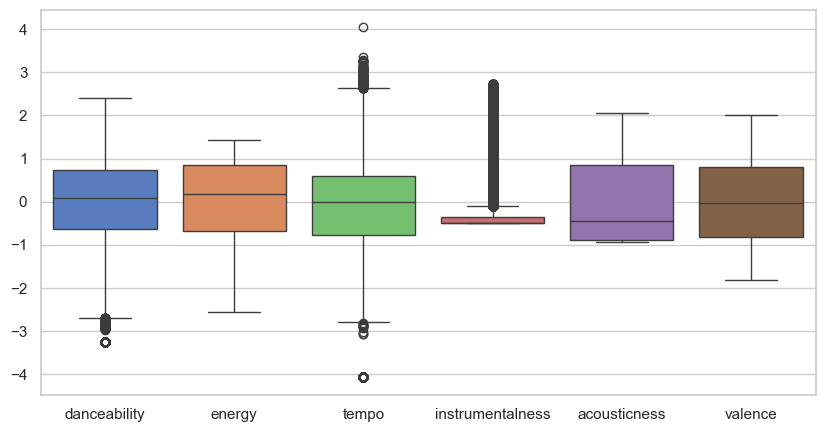

In [10]:
X.describe()
scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)
sns.boxplot(data=X_scaled)


In [11]:
# Your code here

from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
labels = kmeans.fit_predict(X_scaled)

df["kmeans_cluster"] = labels

df["kmeans_cluster"].value_counts()

kmeans_cluster
1    40160
2    29424
3    24961
0    11885
4     7569
Name: count, dtype: int64

<Axes: xlabel='energy', ylabel='valence'>

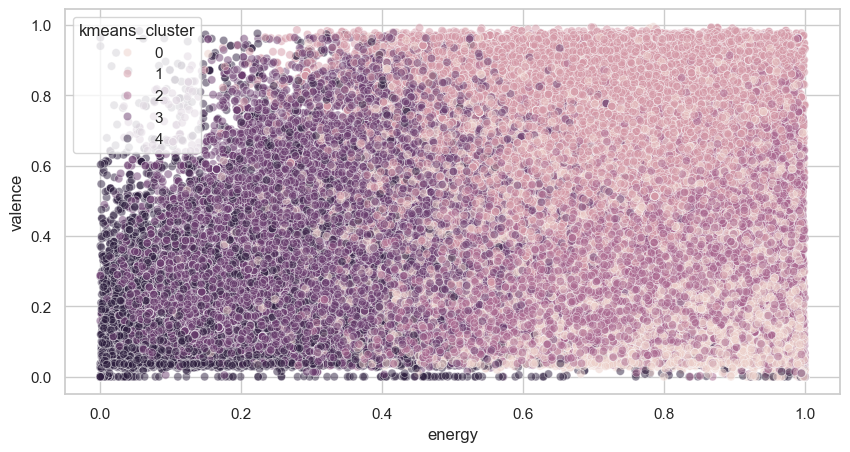

In [12]:
import seaborn as sns

sns.scatterplot(
    data=df,
    x="energy",
    y="valence",
    hue="kmeans_cluster",
    alpha=0.5
)

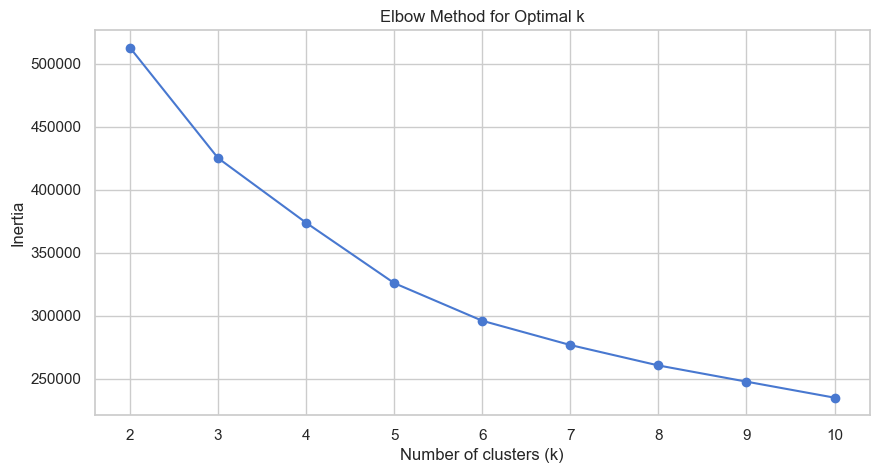

In [13]:
inertias = []

K = range(2, 11)

for k in K:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertias.append(kmeans.inertia_)

plt.plot(K, inertias, marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Optimal k")
plt.show()

In [14]:
from sklearn.metrics import silhouette_score

kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
labels = kmeans.fit_predict(X_scaled)

score = silhouette_score(X_scaled, labels)
print("Silhouette score (k=5):", score)

Silhouette score (k=5): 0.23796144503090316


In [15]:
df.groupby("kmeans_cluster")[feature_cols].mean()

,danceability,energy,tempo,instrumentalness,acousticness,valence
kmeans_cluster,,,,,,
0,0.578492,0.762508,127.566354,0.783590,0.088149,0.334327
1,0.698574,0.723483,117.864751,0.018974,0.216199,0.697358
2,0.470995,0.807559,139.671013,0.029703,0.080446,0.370868
3,0.522735,0.390927,111.432451,0.019566,0.694532,0.385038
4,0.367032,0.195536,103.579768,0.839251,0.854221,0.203499


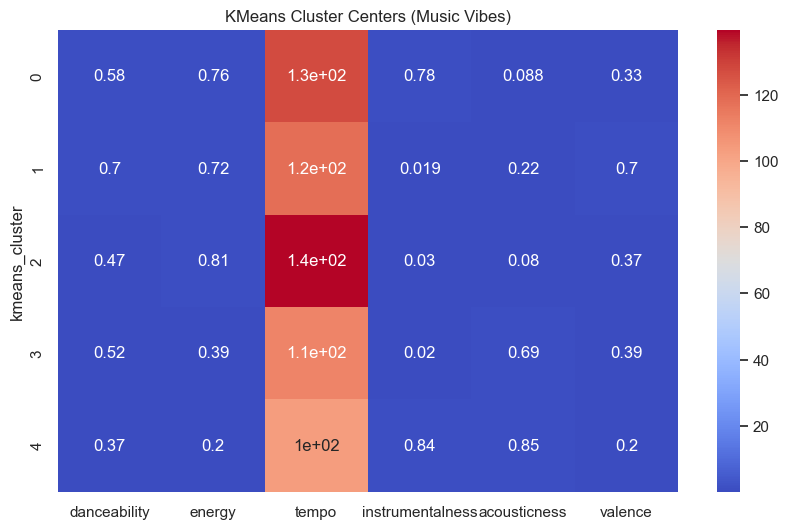

In [16]:
import seaborn as sns
import matplotlib.pyplot as plt

cluster_centers = df.groupby("kmeans_cluster")[feature_cols].mean()

plt.figure(figsize=(10,6))
sns.heatmap(cluster_centers, annot=True, cmap="coolwarm")
plt.title("KMeans Cluster Centers (Music Vibes)")
plt.show()


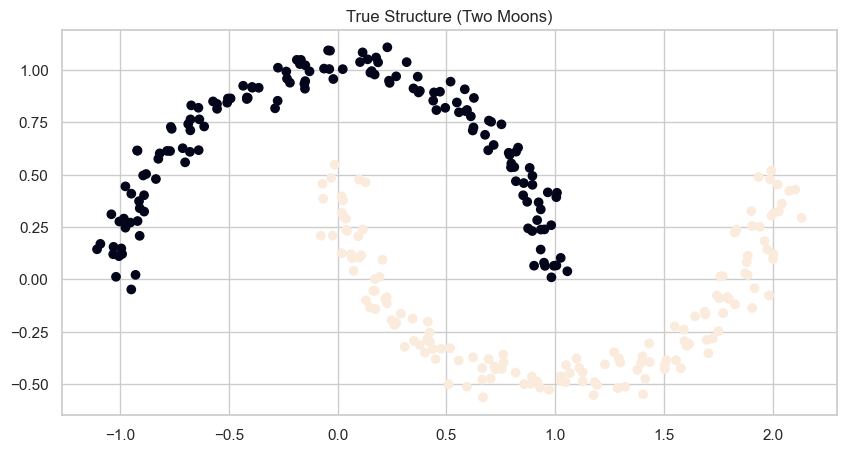

In [17]:
from sklearn.datasets import make_moons
import matplotlib.pyplot as plt

X_moons, y_moons = make_moons(n_samples=300, noise=0.05, random_state=42)

plt.scatter(X_moons[:,0], X_moons[:,1], c=y_moons)
plt.title("True Structure (Two Moons)")
plt.show()

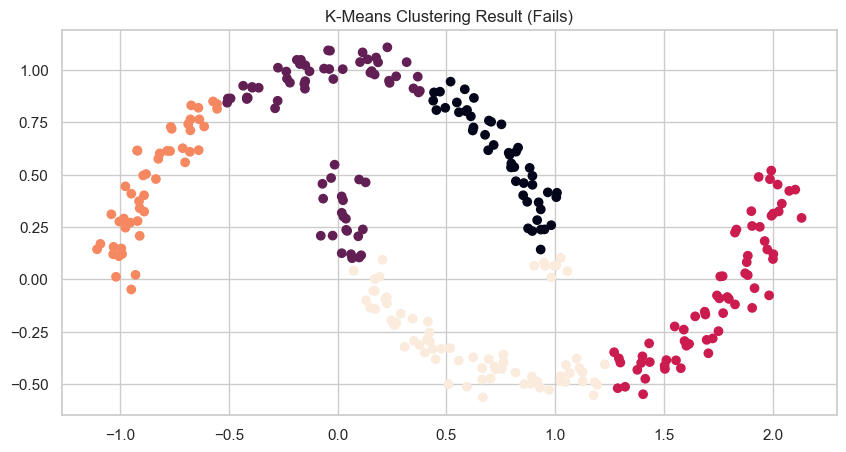

In [18]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
labels = kmeans.fit_predict(X_moons)

plt.scatter(X_moons[:,0], X_moons[:,1], c=labels)
plt.title("K-Means Clustering Result (Fails)")
plt.show()